<a class="anchor" id="0"></a>
# MNIST - Deep Neural Network with Keras

In [4]:

import numpy as np 
import pandas as pd 
import keras

import matplotlib.pyplot as plt 
%matplotlib inline

from keras.models import Sequential
from keras.layers import Dense , Activation, Dropout
from keras.optimizers import Adam ,RMSprop




# 3. MNIST dataset <a class="anchor" id="3"></a>




- MNIST is a collection of handwritten digits ranging from the number 0 to 9. 

- It has a training set of 60,000 images, and 10,000 test images that are classified into corresponding categories or labels. 



In [5]:
# import dataset
from keras.datasets import mnist

# load dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()


# count the number of unique train labels
unique, counts = np.unique(y_train, return_counts=True)
print("Unique train labels: ",dict(zip(unique, counts)))

# count the number of unique test labels
unique, counts = np.unique(y_test, return_counts=True)
print("Unique train labels: ",dict(zip(unique, counts)))


Unique train labels:  {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}
Unique train labels:  {0: 980, 1: 1135, 2: 1032, 3: 1010, 4: 982, 5: 892, 6: 958, 7: 1028, 8: 974, 9: 1009}


# 4. Data visualization <a class="anchor" id="4"></a>




- The following code will help to sample the 25 random MNIST digits and visualize them.

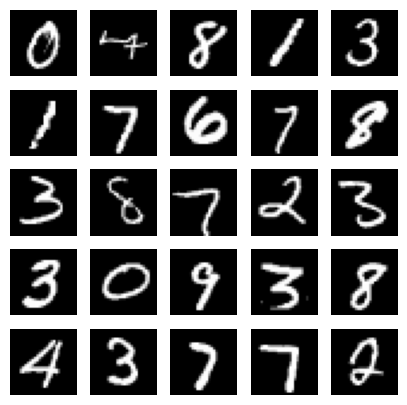

In [8]:
# sample 25 mnist digits from train dataset

indexes = np.random.randint(0, x_train.shape[0], size=25)
images = x_train[indexes]

# plot the 25 mnist digits
plt.figure(figsize=(5,5))
for i in range(len(indexes)):
    plt.subplot(5, 5, i + 1)
    image = images[i]
    plt.imshow(image, cmap='gray')
    plt.axis('off')
    
plt.show()
plt.savefig("mnist-samples.png")
plt.close('all')

# 5. Designing model architecture <a class="anchor" id="5"></a>






---





## 5.1 Import Keras layers <a class="anchor" id="5.1"></a>

In [9]:
from keras.models import Sequential
from keras.layers import Dense, Activation, Dropout
from keras.utils import to_categorical, plot_model

## 5.2 Compute the number of labels <a class="anchor" id="5.2"></a>



In [10]:
# compute the number of labels
num_labels = len(np.unique(y_train))
print("Number of labels:", num_labels)

Number of labels: 10


## 5.3 One-Hot Encoding <a class="anchor" id="5.3"></a>

- At this point, the labels are in digits format, 0 to 9. 

- This sparse scalar representation of labels is not suitable for the neural network prediction layer that outputs probabilities per class. 

- A more suitable format is called a one-hot vector, a 10-dim vector with all elements 0, except for the index of the digit class. 

- For example, if the label is 2, the equivalent one-hot vector is [0,0,1,0,0,0,0,0,0,0]. The first label has index 0.

- The following lines convert each label into a one-hot vector:

In [11]:
# convert to one-hot vector
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

## 5.4 Data Preprocessing <a class="anchor" id="5.4"></a>




In [12]:
# image dimensions (assumed square)
image_size = x_train.shape[1]
input_size = image_size * image_size
print ("Input size:", input_size)

Input size: 784


In [14]:
# resize and normalize
x_train=np.reshape(x_train, [-1, input_size])
x_test=np.reshape(x_test, [-1, input_size])

x_train = x_train.astype('float32')/255
x_test = x_test.astype('float32')/255

In [15]:
x_train.shape

(60000, 784)

In [16]:
x_test.shape

(10000, 784)

## 5.5 Setting network parameters <a class="anchor" id="5.5"></a>

- Now, we will set the network parameters as follows:

In [17]:
# network parameters
batch_size = 128
hidden_units = 256
dropout = 0.45

## 5.6 Designing the model architecture <a class="anchor" id="5.6"></a>




In [19]:
# model is a 3-layer MLP with ReLU and dropout after each layer
classifier = Sequential(name= 'Assignment_2_Model')
classifier.add(Dense(units= hidden_units, input_dim = input_size, activation = 'relu'))
classifier.add(Dropout(dropout))
classifier.add(Dense(units = hidden_units, activation = 'relu'))
classifier.add(Dropout(dropout))
classifier.add(Dense(units= num_labels, activation = 'softmax'))

## 5.7 View model summary <a class="anchor" id="5.7"></a>

- Keras library provides us **summary()** method to check the model description.

In [20]:
# View Model Summary
classifier.summary()

Model: "Assignment_2_Model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 256)               200960    
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense_1 (Dense)             (None, 256)               65792     
                                                                 
 dropout_1 (Dropout)         (None, 256)               0         
                                                                 
 dense_2 (Dense)             (None, 10)                2570      
                                                                 
Total params: 269,322
Trainable params: 269,322
Non-trainable params: 0
_________________________________________________________________



- The total number of parameters required can be computed as follows:

  - From input to Dense layer: 784 × 256 + 256 = 200,960. 
  
  - From first Dense to second Dense: 256 × 256 + 256 = 65,792. 
  
  - From second Dense to the output layer: 10 × 256 + 10 = 2,570. 
  
  - The total is 200,690 + 65,972 + 2,570 = 269,322.

In [23]:
# Plot the model
plot_model(classifier, show_shapes=True)

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.


# 6. Implement MLP model using Keras <a class="anchor" id="6"></a>



## 6.1 Compile the model with compile() method <a class="anchor" id="6.1"></a>


In [25]:
classifier.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

## 6.2 Train the model with fit() method <a class="anchor" id="6.2"></a>

In [26]:
hist=classifier.fit(x_train, y_train, epochs = 100, batch_size = batch_size)

Epoch 1/100


2026-01-11 16:55:42.505977: W tensorflow/tsl/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


469/469 [==============================] - 2s 3ms/step - loss: 0.4310 - accuracy: 0.8673
Epoch 2/100
469/469 [==============================] - 1s 3ms/step - loss: 0.1966 - accuracy: 0.9409
Epoch 3/100
469/469 [==============================] - 1s 3ms/step - loss: 0.1527 - accuracy: 0.9536
Epoch 4/100
469/469 [==============================] - 1s 3ms/step - loss: 0.1292 - accuracy: 0.9610
Epoch 5/100
469/469 [==============================] - 1s 3ms/step - loss: 0.1120 - accuracy: 0.9661
Epoch 6/100
469/469 [==============================] - 1s 3ms/step - loss: 0.1046 - accuracy: 0.9673
Epoch 7/100
469/469 [==============================] - 1s 3ms/step - loss: 0.0938 - accuracy: 0.9706
Epoch 8/100
469/469 [==============================] - 2s 3ms/step - loss: 0.0865 - accuracy: 0.9732
Epoch 9/100
469/469 [==============================] - 1s 3ms/step - loss: 0.0827 - accuracy: 0.9741
Epoch 10/100
469/469 [==============================] - 1s 3ms/step - loss: 0.0764 - accuracy: 0.9756
E

## 6.3 Evaluating model performance with evaluate() method <a class="anchor" id="6.3"></a>

In [27]:
loss, accuracy = classifier.evaluate(x_test, y_test, batch_size=batch_size)

79/79 [==============================] - 0s 1ms/step - loss: 0.0782 - accuracy: 0.9840
